In [ ]:
'''   
Classification Algorithm
  - Binary Class Classification
  - Multi Class Classification

- Stratify
------------------------
- we only need to stratify Target data ( i.e. Y)
- which means we neeed to take equal percentage of target set categories for both traing and testing

suppose
target contains= 70% Healthy and 30% unhealthy

splitting by 80/20 rule then
For Testing 
------------------------------
from 70% healthy -> 40% /10%
from 30% unhealthy -> 40% /10%

For Traning
------------------------------
from 70% healthy -> 40% /10%
from 30% unhealthy -> 40% /10%

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size= 0.2, random_state =42, stratify= Y
)

Logistic Model
------------------------
Arguments for model
   - solver-> 
      1. linlinear,   -> when our dataset is small sized  (0- 30000)
      2. lbfgs(default),  -> if our dataset is medium sized  (30k -below 1 lakhs)
      3. saga             -> if our dataset is large sized (>1 lakhs)
   - calss_weight -> 
       - None(default), 
       - balanced
   - random_state-> 42


Metrics
------------------
-classification report
   - Precisiion
   - recall
   -f1 score
   -support
   - accuracy
   - macro avg
   -weighted avg

- confusion Matrix    -> actual(x_axis) and predicted(y_axis)
   -true positive
   -true negatie
   -fale positive
   -false neagative

   
- ROC-AUC ( only for binary clss classification)

'''

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# import model
from sklearn.linear_model import LogisticRegression

# for splitting
from sklearn.model_selection import train_test_split

# for scaling of data
from sklearn.preprocessing import StandardScaler

# for classification metrics
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score

In [21]:
df= pd.read_csv('Dataset/Cardiovascular_Disease.csv')
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


#### Data cleaning

In [22]:
df['age']= df['age']//365
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,50,2,168,62.0,110,80,1,1,0,0,1,0
1,1,55,1,156,85.0,140,90,3,1,0,0,1,1
2,2,51,1,165,64.0,130,70,3,1,0,0,0,1
3,3,48,2,169,82.0,150,100,1,1,0,0,1,1
4,4,47,1,156,56.0,100,60,1,1,0,0,0,0


<Axes: >

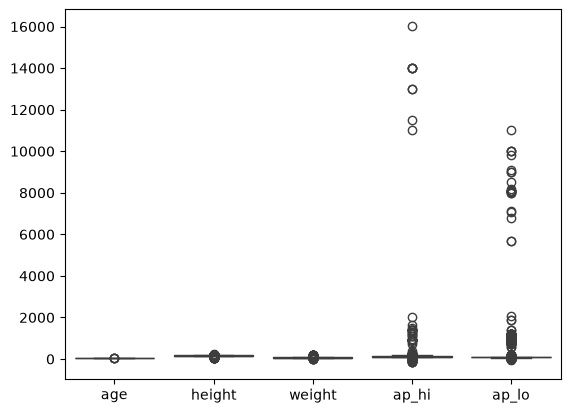

In [23]:
sns.boxplot(df[['age','height','weight','ap_hi','ap_lo']])


In [24]:
df= df[
    (df['height'].between(145,185)) &
    (df['weight'].between(45,120)) &
    (df['ap_hi'].between(90,200)) &
    (df['ap_lo'].between(50,90))
]

In [25]:
df

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,50,2,168,62.0,110,80,1,1,0,0,1,0
1,1,55,1,156,85.0,140,90,3,1,0,0,1,1
2,2,51,1,165,64.0,130,70,3,1,0,0,0,1
4,4,47,1,156,56.0,100,60,1,1,0,0,0,0
5,8,60,1,151,67.0,120,80,2,2,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
69994,99992,57,1,165,80.0,150,80,1,1,0,0,1,1
69995,99993,52,2,168,76.0,120,80,1,1,1,0,1,0
69997,99996,52,2,183,105.0,180,90,3,1,0,1,0,1
69998,99998,61,1,163,72.0,135,80,1,2,0,0,0,1


In [26]:
df.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio'],
      dtype='str')

#### Feature and target

In [30]:
features=['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active']

target ='cardio'

In [31]:
X= df[features]
Y = df[target]

### Train Test Split

In [32]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size= 0.2, random_state =42, stratify= Y
)

### Feature Scaling

In [33]:
scaler= StandardScaler()
X_train_scale= scaler.fit_transform(X_train)
X_test_scale= scaler.transform(X_test)

### Define MOdel

In [37]:
model = LogisticRegression(
    solver='lbfgs',
    class_weight='balanced',
    random_state=42
)
model.fit(X_train_scale, Y_train)
Y_pred= model.predict(X_test_scale)

### Metrics

In [38]:
cr= classification_report(Y_test, Y_pred)
cm= confusion_matrix(Y_test, Y_pred)

In [41]:
print(f'Classification Report')
print('-'*50)
print(cr)

Classification Report
--------------------------------------------------
              precision    recall  f1-score   support

           0       0.72      0.76      0.74      6631
           1       0.71      0.67      0.69      5826

    accuracy                           0.72     12457
   macro avg       0.72      0.72      0.72     12457
weighted avg       0.72      0.72      0.72     12457



In [ ]:
'''   
Macro Avg == Metric1 + metric2 + ------+ metricsn/ n
    - i.e macro avg = (0.72+0.71)/2

weighted Avg == Support1 * metric1 + suppoert2 * metric2 +------------ + supportn +metricn / total support
    - i.e weighted avg = 6631 * 0.72 + 5826 * 0.71 / ( 6631 + 5826)

'''

In [43]:
print(f'Confusion Matrix')
print('-'*25)
print(cm)

Confusion Matrix
-------------------------
[[5071 1560]
 [1947 3879]]


In [ ]:
'''   
TP - 5071
FP - 1560
FN - 1947
TN - 3879

'''

### ROC AUC Curve

In [ ]:
'''   
sigmoid function

threshold -> Default (0.5)

TPR (Y-axis) - tp/(tp-fn)

FPR(X-axis) - fp/(fp-tn)

JScore - Best Threshold position ( TPR - FPR)


'''

In [49]:
# calculation of probabilty

Y_prob = model.predict_proba(X_test_scale)[:,1]
Y_prob

array([0.84512037, 0.68994548, 0.2019743 , ..., 0.45036942, 0.48449602,
       0.4805284 ], shape=(12457,))

In [45]:
# Convert confusion matrix data to one dimension using ravel

tn,fp,fn,tp= cm.ravel()

# calculate TPR and FPR

tpr_default= tp/ (tp- fn)
fpr_default = fp/ (fp- tn)

print(f'True Positive Rate: {tpr_default}')
print(f'False Positive Rate: {fpr_default}')

True Positive Rate: 2.0077639751552794
False Positive Rate: -0.44431785816006836


In [51]:
# Find ROC curve and ROC AUC score data
fpr,tpr, threshold= roc_curve(Y_test, Y_prob)
auc_score = roc_auc_score(Y_test, Y_prob)

print(f'ROC False Positive Rate: {fpr}')
print(f'ROC True Positive Rate: {tpr}')
print(f'ROC Threshold: {threshold}')

ROC False Positive Rate: [0.         0.         0.         ... 0.99819032 0.99819032 1.        ]
ROC True Positive Rate: [0.00000000e+00 1.71644353e-04 5.14933059e-04 ... 9.99828356e-01
 1.00000000e+00 1.00000000e+00]
ROC Threshold: [       inf 0.99742597 0.9957539  ... 0.03431086 0.03409424 0.02431706]


In [53]:
# Calculate JScore for best threshold position

j_score = tpr- fpr
best_idx= np.argmax(j_score)

best_tpr = tpr[best_idx]
best_fpr= fpr[best_idx]
best_threshold= threshold[best_idx]


print(f'Best True Positive Rate: {best_tpr} ')
print(f'Best False Positive Rate: {best_fpr} ')
print(f'Best Threshold: {best_threshold} ')

Best True Positive Rate: 0.6752488843117062 
Best False Positive Rate: 0.24370381541245664 
Best Threshold: 0.493649324237761 


### ROC AUC curve visualization

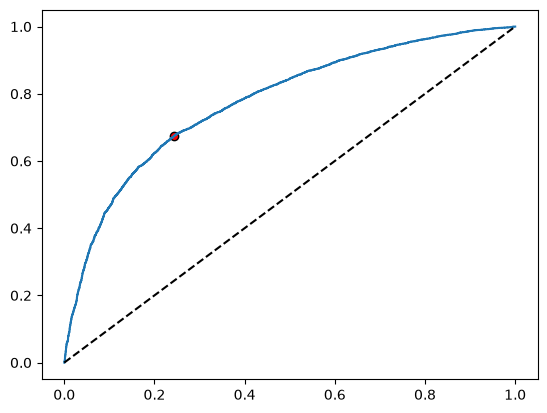

In [58]:
plt.plot(fpr,tpr)
plt.plot([0,1],[0,1],'k--')
plt.scatter(best_fpr, best_tpr, color='red', edgecolors='black')

In [59]:
# calculatiion of probability of new threshold

Y_prob_opt= (Y_prob >= best_threshold).astype(int)
Y_prob_opt

array([1, 1, 0, ..., 0, 0, 0], shape=(12457,))

In [64]:
new_cr= classification_report(Y_test, Y_prob_opt)
new_cm= confusion_matrix(Y_test, Y_prob_opt)



In [65]:
print(new_cr)

              precision    recall  f1-score   support

           0       0.73      0.76      0.74      6631
           1       0.71      0.68      0.69      5826

    accuracy                           0.72     12457
   macro avg       0.72      0.72      0.72     12457
weighted avg       0.72      0.72      0.72     12457



In [66]:
print(new_cm)

[[5015 1616]
 [1892 3934]]


<Axes: >

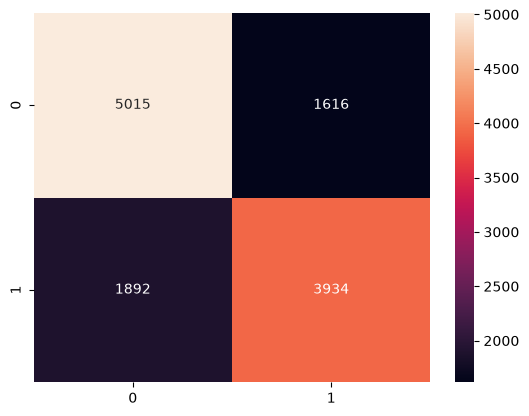

In [70]:
sns.heatmap(new_cm, annot= True, fmt= '0.0f')